# Project 1

Welcome to the first NLP1 project. The goal of the first tutorial was to get you familiar with text segmentation and simple text classification for topic detection.
Given the skills you have developed in the first week, you will now be applying them within a different dataset and task.

We are recommending a set of tasks and associated datasets; using those, you will be experimenting on problems introduced during the tutorials. You will be applying hands-on the experiments you have already explored in the last tutorial, and taking a deeper dive: extending your experiments, trying different set ups, possibly considering different evaluation techniques and analysing errors. 

The week after the deadline, your TA will perform a short oral assessment of the skills and knowledge you acquired (make sure to check the official schedule for this), probing you to answer questions about what you learnt, about what you did and about why you did the things you did (as opposed to some reasonable alternatives) as well as pros and cons of your method, and so on. 

As the tutorials will be building upon your knowledge throughout the weeks, the task and dataset you choose now will be the ones you use in projects 2 and 3; and the ones you will be finally writing about in your final blog post.  

## Get to work!

The next section has a checklist to help you not lose track of what needs to be done. Here we have a more informal guide, with prompts and questions for you. 


1. [Choose a dataset](http://nlp-illc.github.io/nlp1/). Spend some time understanding how the dataset looks and some statistics of it (e.g. how many instances of each classification label we have?)
2. Remember what we learnt during the tutorial: to develop any classifier of the kind we saw, we needed a way to segment text. Do you want to use the tokeniser we have developed? Do you need to train a new one? If you do, what hyperparameters shall you use? What data shall you use to train it? Consider that your dataset may be too small to train a tokeniser! Think whether you will need a larger resource of similar nature to train a tokeniser.
3. Start thinking how to represent your documents into features. We have experimented with token occurences and frequencies. Can you think of any other ways, possibly? 
4. We had experimented with Logistic Regression and a shallow neural network. You can experiment with and assess different architectures now and their hyper parameters (e.g. add layers, possibly change the activation functions, drop out rates).
5. Evaluate your models! Was the evaluation method adequate for your new experimental setup? Do you want to assess other aspects of performance?
6. Analyse the various models you assessed and try to decide on which is the best.

Be mindful that you will be using your experiments to write up your final blog, so make sure they are clean and neat!

You can write your own code and you can reuse code from the tutorial and its packages or from other sources. You may use coding assistants if you like, but use it mindfully as you take full responsibility for this kind of (semi-)automated coding. Also, keep a record of the kinds of things you delegate to any form of assistant, as you will be asked to disclose this in your blog post (not because we will pass a value judgement on it, but because it is a widespread and good practice to document such things).

You may use jupyter notebooks or python files, it's up to you as we will not directly assess your code. But, once again, be organised, as we will ask you to share a reproducible version of your experiments along with your blog post (again, because this is how real research is publicised). 

If you are unsure about anything, ask your TA! They are always happy to help you! Happy coding! :)

## Checklist

What **we expect you to do**:

- [ ] Compare different systems of text classification for your choice of data/task.
- Your comparisons should cover:
    - [ ] the two representation spaces in the tutorial (token indicators and bag-of-words) and an additional one of your choice.
    - [ ] the two kinds of architectures in the tutorial (log-linear and single-hidden-layer MLP) and an additional one of your choice (such as a modification of the MLP).
- [ ] Your comparisons must be based on cross-validation and a relevant metric (accuracy or else).
- [ ] You should make use of Bayesian estimation to help you analyse results in relation to a region of practical equivalence (ROPE), and you can motivate the ROPE size yourself.

What you need to **bring to the oral assessment**:
* You will be asked questions about the points above, you can bring a slide deck with up to five slides (one for each of the following topics _data and metrics_, _features_, _architectures_, _results_, _extra_); you _will not_ give a presentation, rather, these slides are to be thought of as "backup slides" that you can use to guide your answers to the questions the TA will ask you.
* You may also be asked questions about the tutorial, for those, you don't need to prepare any deliverable (a good way to prepare is to work through the tutorial and reflect on the questions there).

What you should **keep in mind** given that you will eventually write a blog post about your work throughout the course:
* Organise your code;
* Summarise your motivations and findings;
* Document your sources and any form of AI-assistance you use.

## LOADS DATA

In [44]:
import os
import kagglehub

path = kagglehub.dataset_download("debarshichanda/goemotions")
print(path)
print(os.listdir(path))

/Users/ioanadumitrache/.cache/kagglehub/datasets/debarshichanda/goemotions/versions/6
['replace_emotions.py', 'tables', 'calculate_metrics.py', 'extract_words.py', 'README.md', 'analyze_data.py', 'GoEmotionsFormat.PNG', 'data', 'goemotions_model_card.pdf', 'plots']


## READS DATA

In [45]:
# import pandas as pd

# train_df = pd.read_csv(os.path.join(path, "data/train.tsv"), sep="\t", header=None, names=["text", "#","labels"])

import os
import pandas as pd

cols = ["text", "labels", "id"]
train_df = pd.read_csv(os.path.join(path, "data/train.tsv"), sep="\t", header=None, names=cols)
dev_df   = pd.read_csv(os.path.join(path, "data/dev.tsv"),   sep="\t", header=None, names=cols)

# keep only the first label for each sample
for df in (train_df, dev_df):
    df["labels"] = df["labels"].str.split(",").str[0].astype(int)

## TOKENIZER

In [46]:
import tokenizer
train_df["text"] = train_df["text"].str.lower()
train_df = tokenizer.tokenize_text(train_df)
train_df = train_df.drop(columns=["id", "text"])
print(train_df.head())

dev_df["text"] = dev_df["text"].str.lower()
dev_df = tokenizer.tokenize_text(dev_df)
dev_df   = dev_df.drop(columns=["id", "text"])

   labels                                        text_tokens
0      27  [my, favourite, food, is, anything, i, did, n'...
1      27  [now, if, he, does, off, himself, ,, everyone,...
2       2              [why, the, fuck, is, bayless, isoing]
3      14                  [to, make, her, feel, threatened]
4       3                         [dirty, southern, wankers]


## REPRESENTATION SPACE

In [47]:
import representation_spaces

vocab = representation_spaces.vocab(train_df)
# print(vocab)
#print(len(vocab))
train_df["token_indicators"] = representation_spaces.token_indicators(train_df["text_tokens"], vocab)
#print(train_df["token_indicators"].head())
#print(train_df["token_indicators"][0].toarray()[0][:20])   # first 20 values of doc 0

train_df["bag_of_words"] = representation_spaces.bag_of_words(train_df["text_tokens"], vocab)
X_tfidf, vectorizer = representation_spaces.tfidf(train_df["text_tokens"])
# train_df["tfidf"] = list(X_tfidf)# first 20 values of doc 0

dev_df["token_indicators"] = representation_spaces.token_indicators(dev_df["text_tokens"], vocab)
dev_df["bag_of_words"]     = representation_spaces.bag_of_words(dev_df["text_tokens"], vocab)
X_tfidf_dev, _             = representation_spaces.tfidf(dev_df["text_tokens"], vectorizer=vectorizer)

In [48]:
# #print(len(vocab[train_df["token_indicators"][0]]))
# print(train_df.head())
# print("########")
# print(train_df["token_indicators"][0].toarray()[0][104])

print(train_df["labels"].dtype, train_df["labels"].nunique())
print(dev_df["labels"].dtype, dev_df["labels"].nunique())
print(train_df["labels"].value_counts().head(10))

int64 28
int64 28
labels
27    12823
0      4130
4      2596
1      2244
3      2138
15     2096
7      1772
10     1651
2      1547
18     1533
Name: count, dtype: int64


In [49]:
from scipy.sparse import vstack

X_ind = vstack(train_df["token_indicators"])
X_bow = vstack(train_df["bag_of_words"])
# X_tfidf = vstack(train_df["tfidf"])
y_train = train_df["labels"]

X_ind_dev = vstack(dev_df["token_indicators"])
X_bow_dev = vstack(dev_df["bag_of_words"])
y_dev     = dev_df["labels"]

print(X_ind.shape,   X_ind_dev.shape)
print(X_bow.shape,   X_bow_dev.shape)
print(X_tfidf.shape, X_tfidf_dev.shape)

(43410, 28848) (5426, 28848)
(43410, 28848) (5426, 28848)
(43410, 28848) (5426, 28848)


## MLP

In [50]:
import architecture
from sklearn.metrics import f1_score

In [51]:

# token indicator
mlp_ind = architecture.build_mlp()
mlp_ind.fit(X_ind, y_train)
print("ind + MLP    train:", mlp_ind.score(X_ind, y_train))
print("ind + MLP    dev:  ", mlp_ind.score(X_ind_dev, y_dev))
print("ind + MLP    dev f1:", f1_score(y_dev, mlp_ind.predict(X_ind_dev), average="macro")) 

Iteration 1, loss = 2.81010475
Validation score: 0.392997
Iteration 2, loss = 2.12695360
Validation score: 0.484220
Iteration 3, loss = 1.60993859
Validation score: 0.515089
Iteration 4, loss = 1.27458946
Validation score: 0.526146
Iteration 5, loss = 1.04820423
Validation score: 0.526146
Iteration 6, loss = 0.88280795
Validation score: 0.528680
Iteration 7, loss = 0.75628718
Validation score: 0.524994
Iteration 8, loss = 0.65771477
Validation score: 0.522460
Iteration 9, loss = 0.57930391
Validation score: 0.520387
Iteration 10, loss = 0.51565000
Validation score: 0.516471
Validation score did not improve more than tol=0.000100 for 3 consecutive epochs. Stopping.
ind + MLP    train: 0.7660677263303386
ind + MLP    dev:   0.5311463324732768
ind + MLP    dev f1: 0.3743802122314032


In [52]:
# bag-of-words
mlp_bow = architecture.build_mlp()
mlp_bow.fit(X_bow, y_train)
print("bow + MLP    train:", mlp_bow.score(X_bow, y_train))
print("bow + MLP    dev:  ", mlp_bow.score(X_bow_dev, y_dev))
print("bow + MLP    dev f1:", f1_score(y_dev, mlp_bow.predict(X_bow_dev), average="macro"))

Iteration 1, loss = 2.80730169
Validation score: 0.401981
Iteration 2, loss = 2.13658605
Validation score: 0.480534
Iteration 3, loss = 1.62843107
Validation score: 0.509330
Iteration 4, loss = 1.29881180
Validation score: 0.519696
Iteration 5, loss = 1.07345828
Validation score: 0.523151
Iteration 6, loss = 0.90587356
Validation score: 0.521308
Iteration 7, loss = 0.77664026
Validation score: 0.519926
Iteration 8, loss = 0.67521341
Validation score: 0.519235
Iteration 9, loss = 0.59466237
Validation score: 0.513246
Validation score did not improve more than tol=0.000100 for 3 consecutive epochs. Stopping.
bow + MLP    train: 0.7243722644551946
bow + MLP    dev:   0.5298562476962771
bow + MLP    dev f1: 0.36361788051442234


In [53]:
# tfidf
mlp_tfidf = architecture.build_mlp()
mlp_tfidf.fit(X_tfidf, y_train)
print("tfidf + MLP  train:", mlp_tfidf.score(X_tfidf, y_train))
print("tfidf + MLP  dev:  ", mlp_tfidf.score(X_tfidf_dev, y_dev))
print("tfidf + MLP  dev macro-F1:", f1_score(y_dev, mlp_tfidf.predict(X_tfidf_dev), average="macro"))


Iteration 1, loss = 3.00509742
Validation score: 0.303156
Iteration 2, loss = 2.51164548
Validation score: 0.368579
Iteration 3, loss = 2.13725032
Validation score: 0.426860
Iteration 4, loss = 1.78129591
Validation score: 0.468556
Iteration 5, loss = 1.49425254
Validation score: 0.492053
Iteration 6, loss = 1.26966906
Validation score: 0.497351
Iteration 7, loss = 1.09429859
Validation score: 0.499885
Iteration 8, loss = 0.95569108
Validation score: 0.497351
Iteration 9, loss = 0.84380070
Validation score: 0.496890
Iteration 10, loss = 0.75225225
Validation score: 0.498733
Iteration 11, loss = 0.67673294
Validation score: 0.491822
Validation score did not improve more than tol=0.000100 for 3 consecutive epochs. Stopping.
tfidf + MLP  train: 0.7129002533978346
tfidf + MLP  dev:   0.5023958717287136
tfidf + MLP  dev macro-F1: 0.3267478311807161


Iteration 1, loss = 3.00509742
Validation score: 0.303156
Iteration 2, loss = 2.51164548
Validation score: 0.368579
Iteration 3, loss = 2.13725032
Validation score: 0.426860
Iteration 4, loss = 1.78129591
Validation score: 0.468556
Iteration 5, loss = 1.49425254
Validation score: 0.492053
Iteration 6, loss = 1.26966906
Validation score: 0.497351
Iteration 7, loss = 1.09429859
Validation score: 0.499885
Iteration 8, loss = 0.95569108
Validation score: 0.497351
Iteration 9, loss = 0.84380070
Validation score: 0.496890
Iteration 10, loss = 0.75225225
Validation score: 0.498733
Iteration 11, loss = 0.67673294
Validation score: 0.491822
Validation score did not improve more than tol=0.000100 for 3 consecutive epochs. Stopping.
epochs run: 11
train loss per epoch: [np.float64(3.005), np.float64(2.512), np.float64(2.137), np.float64(1.781), np.float64(1.494), np.float64(1.27), np.float64(1.094), np.float64(0.956), np.float64(0.844), np.float64(0.752), np.float64(0.677)]
val accuracy per epoch

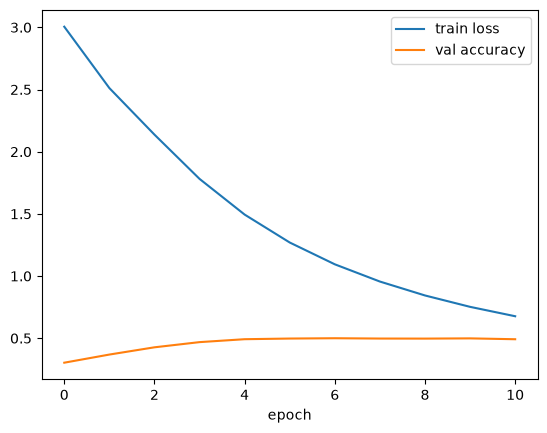

In [54]:
import matplotlib.pyplot as plt
from sklearn.metrics import log_loss

m = architecture.build_mlp()
m.fit(X_tfidf, y_train)

print("epochs run:", m.n_iter_)
print("train loss per epoch:", [round(x, 3) for x in m.loss_curve_])
print("val accuracy per epoch:", [round(x, 3) for x in m.validation_scores_])
print("dev log-loss:", log_loss(y_dev, m.predict_proba(X_tfidf_dev), labels=m.classes_))

plt.plot(m.loss_curve_, label="train loss")
plt.plot(m.validation_scores_, label="val accuracy")
plt.legend(); plt.xlabel("epoch"); plt.show()